# Розпізнавання рукописних цифр: моделі та стійкість
**Дослідницький проєкт · MNIST · scikit-learn · PyTorch**

Автор: ____________________ · Група: ____________________

Мета: порівняти лінійний класифікатор, MLP та CNN і перевірити, як геометрична аугментація впливає на чисту якість і стійкість. Це навчання з нуля готових бібліотечних моделей, а не донавчання.

**Про виконання:** моделі фактично навчені скриптом `experiment.py`. Notebook показує їхній код, збережені історії та результати. За замовчуванням він повторно не витрачає час на навчання. Для повного відтворення встановіть `RETRAIN=True`; автоматичне перевикористання завершених запусків пояснене нижче.

In [1]:
from pathlib import Path
import sys, json, inspect, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image, Code
ROOT = Path.cwd() if (Path.cwd()/'config.json').exists() else Path.cwd()/'mnist_project'
sys.path.insert(0, str(ROOT))
OUT = ROOT/'artifacts'
config = json.loads((ROOT/'config.json').read_text())
display(config)

{'seeds': [17, 42, 73],
 'epochs': 6,
 'batch_size': 256,
 'learning_rate': 0.001,
 'weight_decay': 0.0001,
 'threads': 2,
 'validation_size': 10000,
 'split_seed': 42,
 'selection': 'validation_macro_f1',
 'augmentation': {'rotation_degrees': 15,
  'translation_fraction': 0.1,
  'scale': [0.9, 1.1]},
 'conditions': ['clean',
  'rotate_plus20',
  'rotate_minus20',
  'shift_right3',
  'noise_020',
  'thick',
  'thin']}

## 1. План до відкриття test
MNIST має 60000 офіційних train і 10000 test. Із train виділяємо 50000/10000 для навчання/валідації (stratified, seed=42). Для нейромереж seeds=17,42,73, шість епох, Adam, batch=256. Найкраща епоха визначається за validation macro-F1.

Гіпотеза 1: CNN перевершує логістичну регресію в цьому протоколі. Гіпотеза 2: аугментація покращує середню accuracy на +20°, −20° і зсуві 3 px. Чиста якість перевіряється окремо. Шум і товщина — додаткові stress tests, а не підстава змінювати модель.

In [2]:
from data import split_indices, augment_batch, CONDITIONS
display(Code(inspect.getsource(split_indices), language='python'))
if (OUT/'split.npz').exists():
    split = np.load(OUT/'split.npz')
    assert not set(split['train']) & set(split['validation'])
    print('Train:',len(split['train']),'Validation:',len(split['validation']),'Official test: 10000')

def split_indices(labels, validation_size=10000):
    return train_test_split(np.arange(len(labels)), test_size=validation_size,
                            stratify=labels, random_state=42)

Train: 50000 Validation: 10000 Official test: 10000


## 2. Дані й підготовка
Вхід має форму [batch,1,28,28]. Для регресії зображення розгортається у 784 ознаки. Пікселі ділимо на 255; нейромережам додатково задаємо фіксований масштаб −1…1 без fitted statistics. Дані завантажує `torchvision.datasets.MNIST`.

Виконайте наступну клітинку для відтворення або використайте вже отримані артефакти. `experiment.py` відновлює роботу на рівні завершеного запуску. Щоб справді перенавчити всі моделі, спочатку перейменуйте папку `artifacts` як резервну копію. Не змінюйте протокол, спираючись на test-результати.

In [3]:
RETRAIN = False
if RETRAIN or not (OUT/'training_summary.csv').exists():
    subprocess.run([sys.executable,str(ROOT/'experiment.py')],check=True,cwd=ROOT)
    subprocess.run([sys.executable,str(ROOT/'evaluate.py')],check=True,cwd=ROOT)
    subprocess.run([sys.executable,str(ROOT/'report.py')],check=True,cwd=ROOT)
else:
    print('Використовуємо результати фактично завершеного навчання. Повторне навчання вимкнено.')
    if not (OUT/'evaluation.json').exists():
        subprocess.run([sys.executable,str(ROOT/'evaluate.py')],check=True,cwd=ROOT)
    if not (ROOT/'REPORT.md').exists() or not (OUT/'figures'/'reliability.png').exists():
        subprocess.run([sys.executable,str(ROOT/'report.py')],check=True,cwd=ROOT)
display(json.loads((OUT/'environment.json').read_text()))

Використовуємо результати фактично завершеного навчання. Повторне навчання вимкнено.


{'versions': {'python': '3.12.14',
  'torch': '2.15.0+cpu',
  'sklearn': '1.9.1',
  'numpy': '2.5.4',
  'pandas': '3.1.1',
  'device': 'cpu',
  'threads': 2},
 'raw_sha256': {'t10k-images-idx3-ubyte.gz': '8d422c7b0a1c1c79245a5bcf07fe86e33eeafee792b84584aec276f5a2dbc4e6',
  't10k-labels-idx1-ubyte.gz': 'f7ae60f92e00ec6debd23a6088c31dbd2371eca3ffa0defaefb259924204aec6',
  'train-images-idx3-ubyte.gz': '440fcabf73cc546fa21475e81ea370265605f56be210a4024d2ca8f203523609',
  'train-labels-idx1-ubyte.gz': '3552534a0a558bbed6aed32b30c495cca23d567ec52cac8be1a0730e8010255c'}}

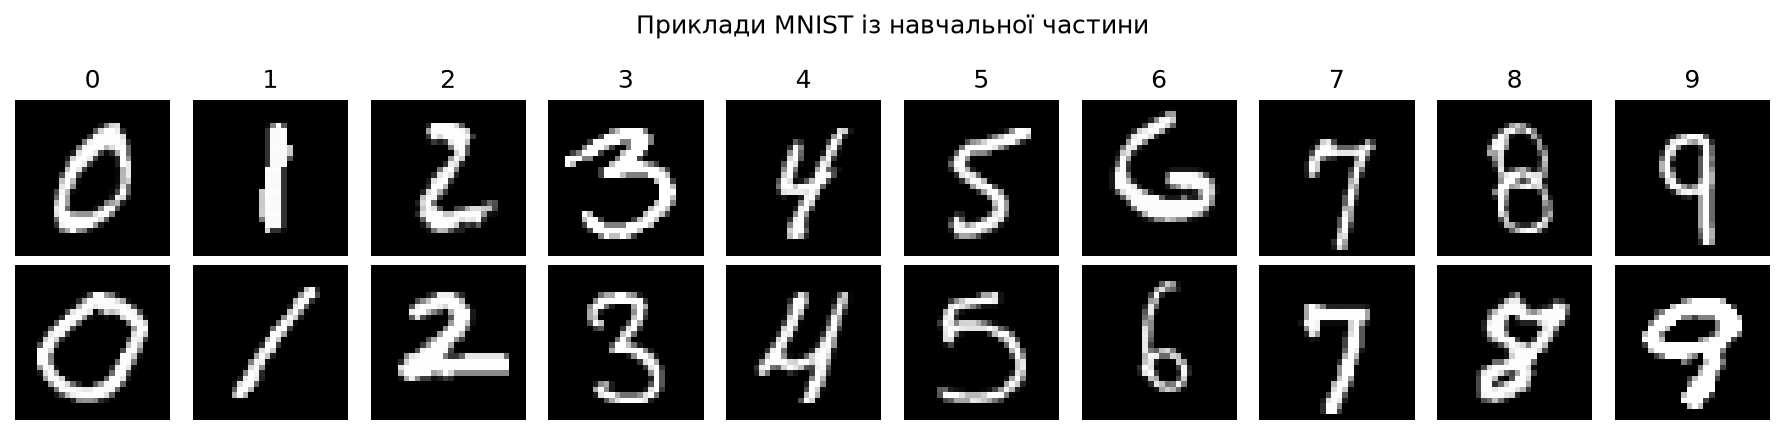

,digit,train,validation,test
0,0,4936,987,980
1,1,5618,1124,1135
2,2,4965,993,1032
3,3,5109,1022,1010
4,4,4868,974,982
5,5,4518,903,892
6,6,4932,986,958
7,7,5221,1044,1028
8,8,4876,975,974
9,9,4957,992,1009


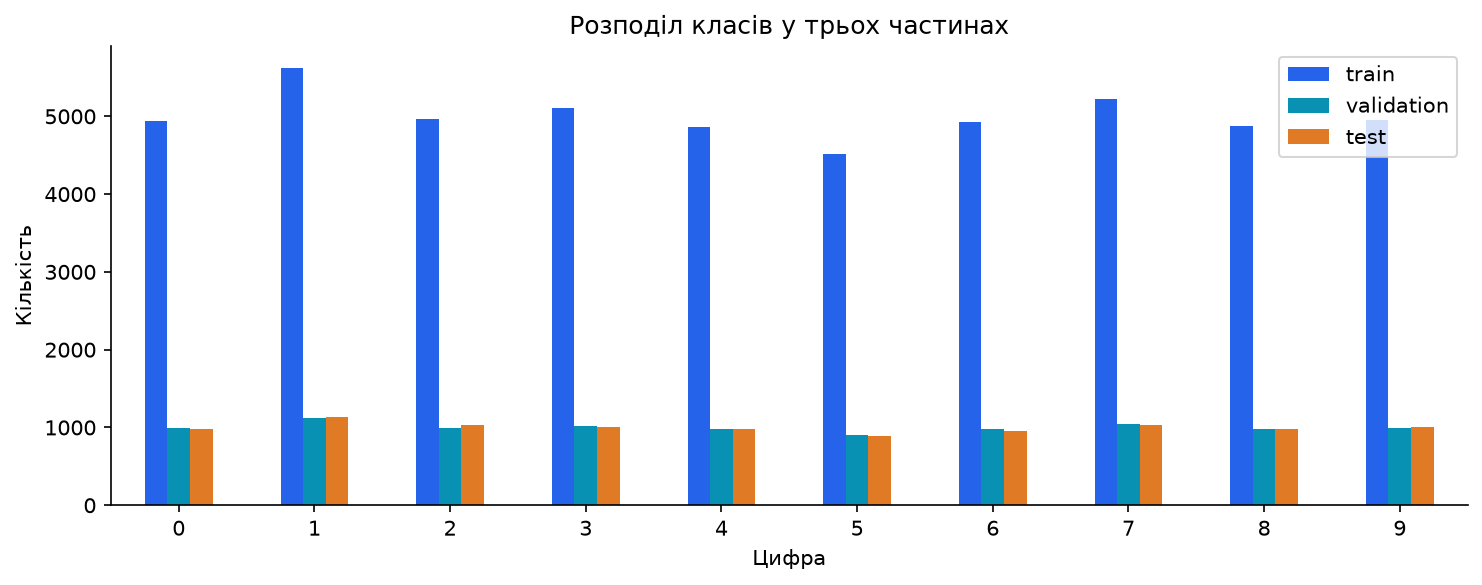

In [4]:
display(Image(filename=str(OUT/'figures'/'samples.png')))
display(pd.read_csv(OUT/'class_balance.csv'))
display(Image(filename=str(OUT/'figures'/'class_balance.png')))

## 3. Архітектури
MLP порівнюємо зі згортковою мережею. CNN і CNN_aug мають однакову архітектуру; змінюється лише навчальна передобробка. Dropout активний під час навчання та вимкнений під час оцінювання.

In [5]:
from models import make_model
import torch
display(Code(inspect.getsource(make_model),language='python'))
for kind in ['mlp','cnn']:
    model=make_model(kind)
    print(kind,':',sum(p.numel() for p in model.parameters()),'параметрів; logits',tuple(model(torch.zeros(2,1,28,28)).shape))

def make_model(kind):
    if kind == 'mlp':
        return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                             nn.Dropout(0.2), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))
    if kind == 'cnn':
        return nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Flatten(), nn.Linear(16 * 7 * 7, 64), nn.ReLU(),
                             nn.Dropout(0.2), nn.Linear(64, 10))
    raise ValueError(f'Unknown architecture: {kind}')

mlp : 109386 параметрів; logits (2, 10)
cnn : 52138 параметрів; logits (2, 10)


## 4. Реалізація навчання
Нижче наведено фактичний training loop із модуля `experiment.py`: `zero_grad → forward → CrossEntropyLoss → backward → optimizer.step`. Backpropagation виконує PyTorch autograd. CrossEntropyLoss отримує logits, без попереднього softmax. Після кожної епохи модель перевіряється на validation; test у функцію навчання не передається.

In [6]:
import experiment
display(Code(inspect.getsource(experiment.evaluate_validation),language='python'))
display(Code(inspect.getsource(experiment.run),language='python'))

def evaluate_validation(model, x, y):
    model.eval()
    losses, predictions = 0., []
    with torch.inference_mode():
        for start in range(0, len(x), 512):
            logits = model(normalize(x[start:start+512]))
            losses += nn.functional.cross_entropy(logits, y[start:start+512], reduction='sum').item()
            predictions.extend(logits.argmax(1).tolist())
    return losses / len(x), accuracy_score(y, predictions), f1_score(y, predictions, average='macro')

def run(config_path=ROOT / 'config.json'):
    cfg = json.loads(Path(config_path).read_text(encoding='utf-8'))
    OUT.mkdir(exist_ok=True)
    (OUT / 'checkpoints').mkdir(exist_ok=True)
    protocol_path = OUT / 'protocol.json'
    if protocol_path.exists() and json.loads(protocol_path.read_text()) != cfg:
        raise ValueError('Existing artifacts use a different protocol. Choose a fresh output directory.')
    protocol_path.write_text(json.dumps(cfg, indent=2), encoding='utf-8')
    torch.set_num_threads(cfg['threads'])
    x, y, xv, yv, a, b = load_training(validation_size=cfg['validation_size'], split_seed=cfg['split_seed'])
    np.savez_compressed(OUT / 'split.npz', train=a, validation=b)
    versions = {'python': platform.python_version(), 'torch': torch.__version__, 'sklearn': sklearn.__version__, 'numpy': np.__version__, 'pandas': pd.__version__, 'device': 'cpu', 'threads': cfg['threads']}
    (OUT / 'environment.json').write_text(json.dumps({'versions': versions, 'raw_sha256': raw_hashes()}, indent=2), encoding='utf-8')
    records = []
    for name, architecture, augmentation in [('MLP', 'mlp', False), ('CNN', 'cnn', False), ('CNN_aug', 'cnn', True)]:
        for seed in cfg['seeds']:
            key = f'{name}_{seed}'
            metadata_path = OUT / f'{key}.json'
            if metadata_path.exists():
                records.append(json.loads(metadata_path.read_text()))
                print(f'Reuse completed {key}', flush=True)
                continue
            set_seed(seed)
            model = make_model(architecture)
            initial_sha = hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in model.parameters())).hexdigest()
            optimizer = torch.optim.Adam(model.parameters(), lr=cfg['learning_rate'], weight_decay=cfg['weight_decay'])
            loader = DataLoader(TensorDataset(x, y), batch_size=cfg['batch_size'], shuffle=True,
                                generator=torch.Generator().manual_seed(seed), num_workers=0)
            aug_rng = torch.Generator().manual_seed(seed + 10000)
            best, history, selected_epoch = -1., [], 0
            start = time.perf_counter()
            for epoch in range(1, cfg['epochs'] + 1):
                model.train()
                total_loss, correct, total = 0., 0, 0
                for xb, yb in loader:
                    if augmentation:
                        aug = cfg['augmentation']
                        xb = augment_batch(xb, aug_rng, aug['rotation_degrees'], aug['translation_fraction'], aug['scale'])
                    optimizer.zero_grad(set_to_none=True)
                    logits = model(normalize(xb))
                    loss = nn.functional.cross_entropy(logits, yb)
                    loss.backward()  # PyTorch autograd; no handwritten backpropagation
                    optimizer.step()
                    total_loss += loss.item() * len(yb)
                    correct += int((logits.argmax(1) == yb).sum())
                    total += len(yb)
                val_loss, val_accuracy, val_f1 = evaluate_validation(model, xv, yv)
                row = {'epoch': epoch, 'train_loss': total_loss/total, 'train_accuracy': correct/total,
                       'validation_loss': val_loss, 'validation_accuracy': val_accuracy, 'validation_macro_f1': val_f1}
                history.append(row)
                if val_f1 > best:
                    best, selected_epoch = val_f1, epoch
                    checkpoint = {'state_dict': copy.deepcopy(model.state_dict()), 'architecture': architecture,
                                  'name': name, 'seed': seed, 'epoch': epoch, 'validation_macro_f1': float(best)}
                    torch.save(checkpoint, OUT / 'checkpoints' / f'{key}.pt')
                print(f'{key} epoch={epoch}/{cfg["epochs"]} loss={row["train_loss"]:.4f} val_f1={val_f1:.4f}', flush=True)
            pd.DataFrame(history).to_csv(OUT / f'history_{key}.csv', index=False)
            metadata = {'name': name, 'seed': see

## 5. Історії та вибір checkpoint
Графіки показують mean ± sample std трьох запусків. Train метрики отримані в train-режимі під час оновлень ваг; validation — в eval після епохи. Для CNN_aug train також спотворений. Тому пряме порівняння train і validation має це обмеження. Всі шість епох виконуються; збереження найкращої епохи не є early stopping.

,name,seed,validation_macro_f1,selected_epoch,parameters,training_seconds
0,MLP,17,0.9634,6.0,109386,10.6396
1,MLP,42,0.9597,6.0,109386,11.1471
2,MLP,73,0.9585,6.0,109386,11.5432
3,CNN,17,0.9809,6.0,52138,73.1837
4,CNN,42,0.9818,6.0,52138,75.1645
5,CNN,73,0.9810,6.0,52138,78.7547
6,CNN_aug,17,0.9768,5.0,52138,80.7822
7,CNN_aug,42,0.9792,6.0,52138,75.7061
8,CNN_aug,73,0.9735,6.0,52138,79.6734
9,LogisticRegression,42,0.9204,NaN,7850,5.2100


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1
0,1,1.1061,0.6437,0.2060,0.9445,0.9446
1,2,0.3775,0.8848,0.1310,0.9612,0.9614
2,3,0.2622,0.9193,0.0872,0.9752,0.9751
3,4,0.2205,0.9332,0.0871,0.9743,0.9743
4,5,0.1938,0.9418,0.0727,0.9783,0.9782
5,6,0.1804,0.9434,0.0685,0.9793,0.9792


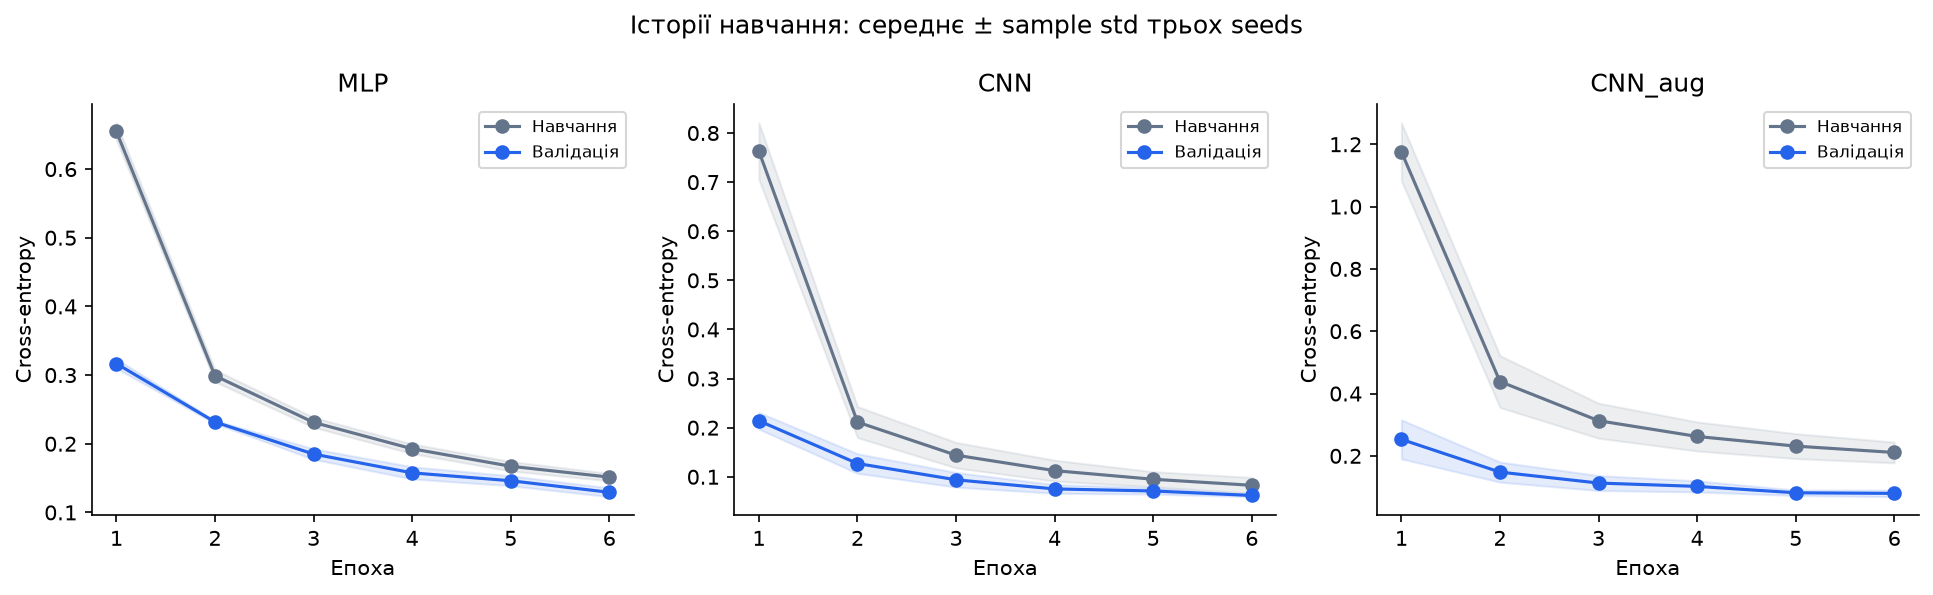

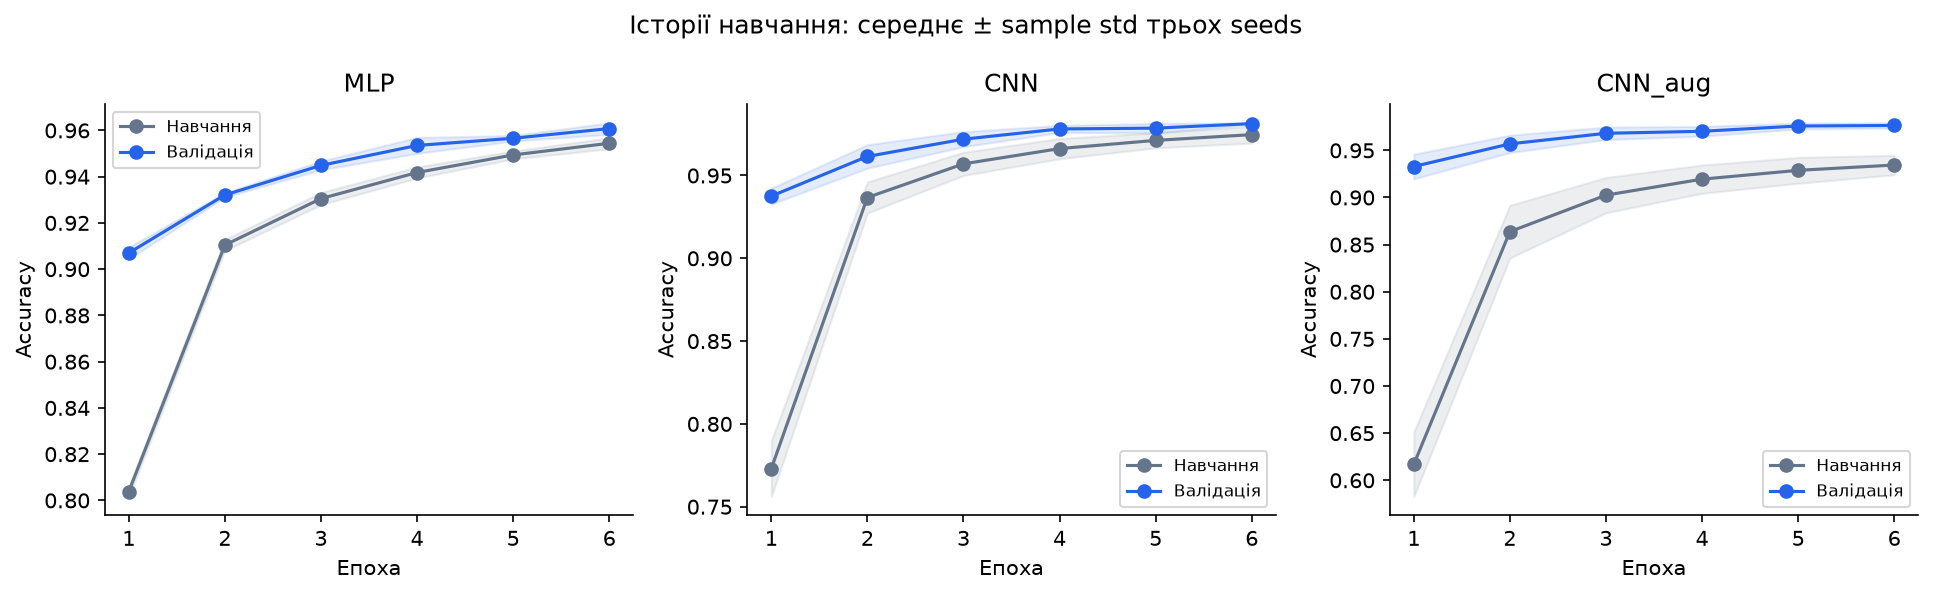

In [7]:
training=pd.read_csv(OUT/'training_summary.csv')
display(training[['name','seed','validation_macro_f1','selected_epoch','parameters','training_seconds']].round(4))
display(pd.read_csv(OUT/'history_CNN_aug_42.csv').round(4))
display(Image(filename=str(OUT/'figures'/'loss_curves.png')))
display(Image(filename=str(OUT/'figures'/'accuracy_curves.png')))

## 6. Контрольований експеримент з аугментацією
Поворот ±15°, зсув ±10%, масштаб 0.9…1.1 — незалежно для кожного зображення. Перетворення реалізовані бібліотечними операціями. У парі з однаковим seed CNN і CNN_aug починають із тих самих ваг; перевіримо це за hashes. Shuffle і аугментація використовують окремі generators.

In [8]:
display(Code(inspect.getsource(augment_batch),language='python'))
for seed in config['seeds']:
    plain=json.loads((OUT/f'CNN_{seed}.json').read_text())
    aug=json.loads((OUT/f'CNN_aug_{seed}.json').read_text())
    assert plain['initial_weights_sha256']==aug['initial_weights_sha256']
    print(seed,': початкові ваги однакові')

def augment_batch(x, generator=None, degrees=15, translation=0.1, scale_range=(0.9, 1.1)):
    """Independent affine transform per image. No learned algorithm implemented here."""
    n = len(x)
    angles = (torch.rand(n, generator=generator) * 2 - 1) * degrees * torch.pi / 180
    scales = scale_range[0] + (scale_range[1]-scale_range[0]) * torch.rand(n, generator=generator)
    translations = (torch.rand(n, 2, generator=generator) * 2 - 1) * (2 * translation)
    theta = torch.zeros(n, 2, 3)
    theta[:, 0, 0] = angles.cos() / scales
    theta[:, 1, 1] = angles.cos() / scales
    theta[:, 0, 1] = -angles.sin() / scales
    theta[:, 1, 0] = angles.sin() / scales
    theta[:, :, 2] = translations
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, mode='bilinear', padding_mode='zeros', align_corners=False).clamp(0, 1)

17 : початкові ваги однакові
42 : початкові ваги однакові
73 : початкові ваги однакові


## 7. Незалежне оцінювання на чистому test
Accuracy — частка правильних прогнозів. Macro-F1 — середнє F1 класів, які мають рівну вагу. Результати всіх seeds показано, а не відібрано за найкращим test. Для регресії є один детермінований запуск; std не визначено. Test-прогнози можна перевірити у `predictions.npz`.

,name,condition,n,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
0,LogisticRegression,clean,1,0.92080,NaN,0.91972,NaN
1,MLP,clean,3,0.96257,0.00249,0.96222,0.00253
2,CNN,clean,3,0.98287,0.00140,0.98275,0.00143
3,CNN_aug,clean,3,0.97900,0.00322,0.97898,0.00318


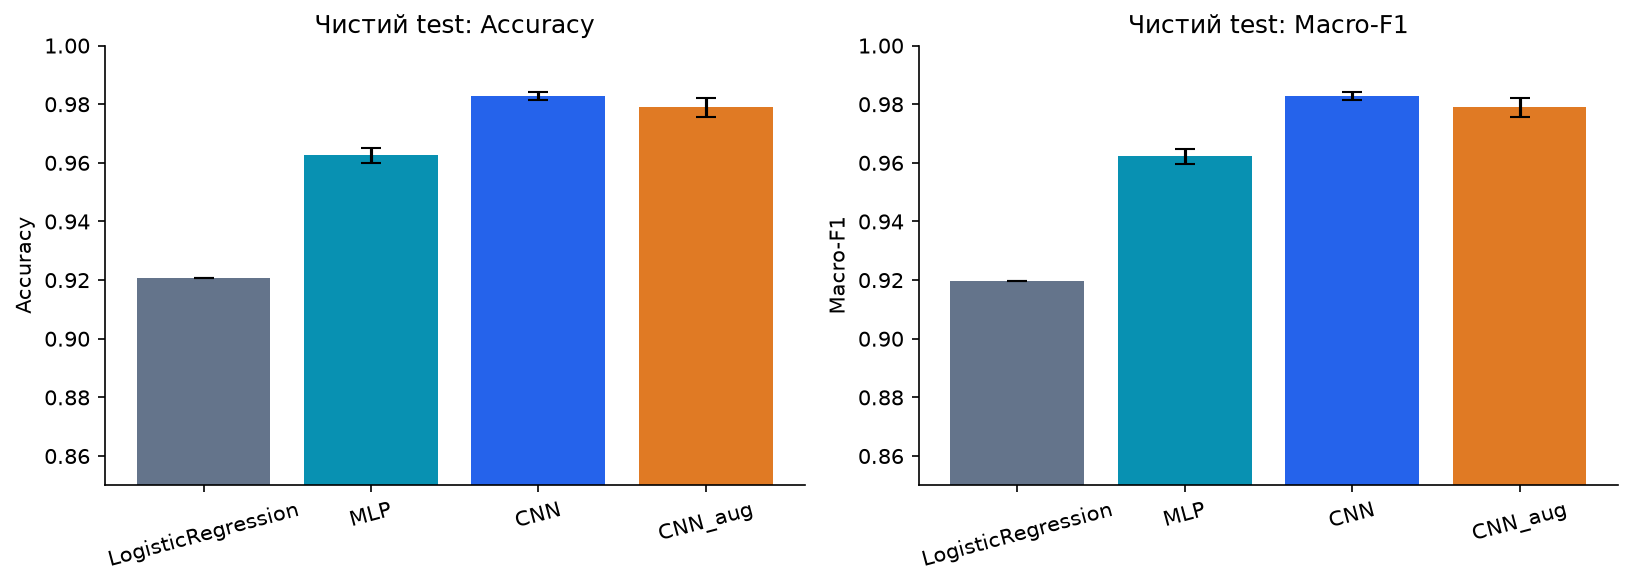

Збережені прогнози узгоджені з accuracy всіх 10 запусків.


In [9]:
evaluation=json.loads((OUT/'evaluation.json').read_text())
clean=pd.read_csv(OUT/'clean_summary.csv')
display(clean.round(5))
display(Image(filename=str(OUT/'figures'/'clean_comparison.png')))
predictions=np.load(OUT/'predictions.npz')
for run in evaluation['runs']:
    key=f"{run['name']}_{run['seed']}__clean"
    actual=float((predictions[key]==predictions['truth']).mean())
    assert abs(actual-run['conditions']['clean']['accuracy'])<1e-12
print('Збережені прогнози узгоджені з accuracy всіх 10 запусків.')

## 8. Наперед задані stress tests
±20° і зсув праворуч 3 px перевіряють перенесення геометричної стійкості. Gaussian noise σ=0.2 та dilation/erosion 3×3 — інші типи зміни розподілу. Кожне спотворення застосовується окремо до чистого test; моделі отримують ідентичні входи й не перенавчаються.

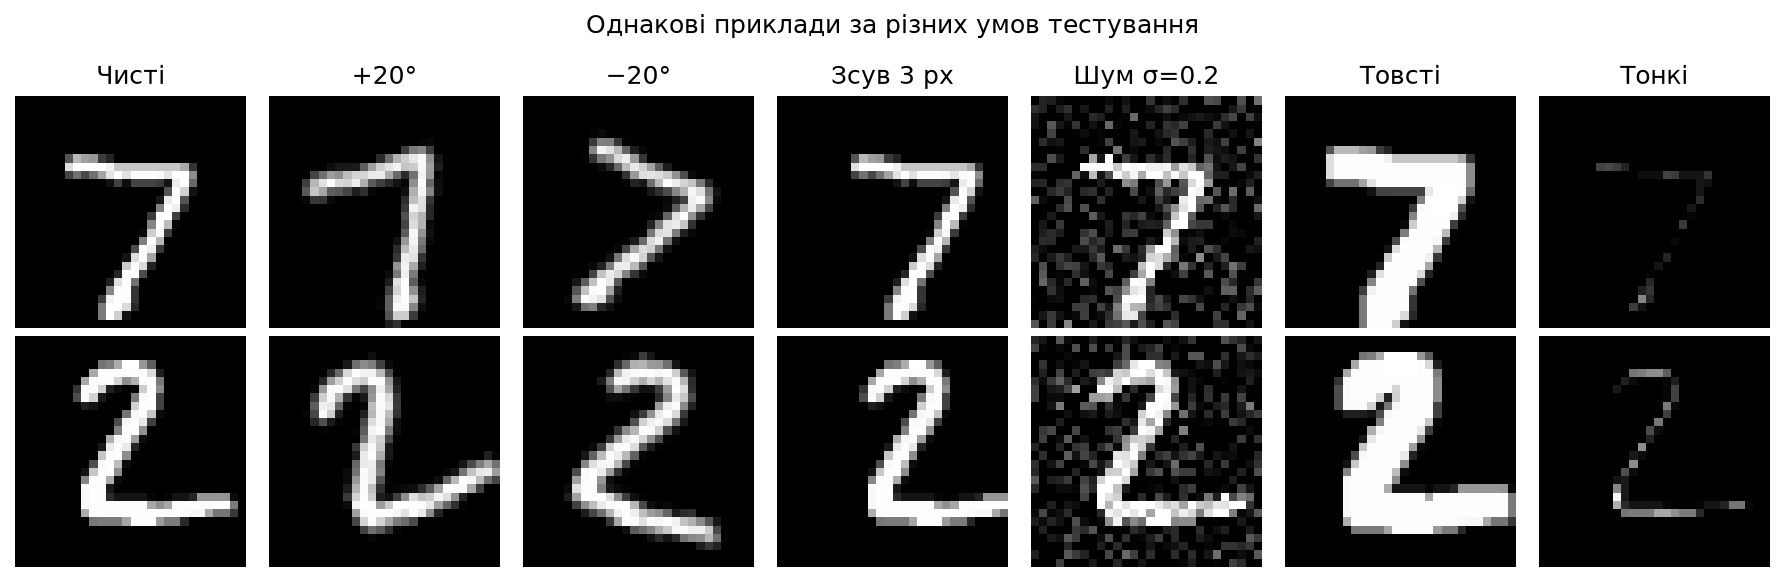

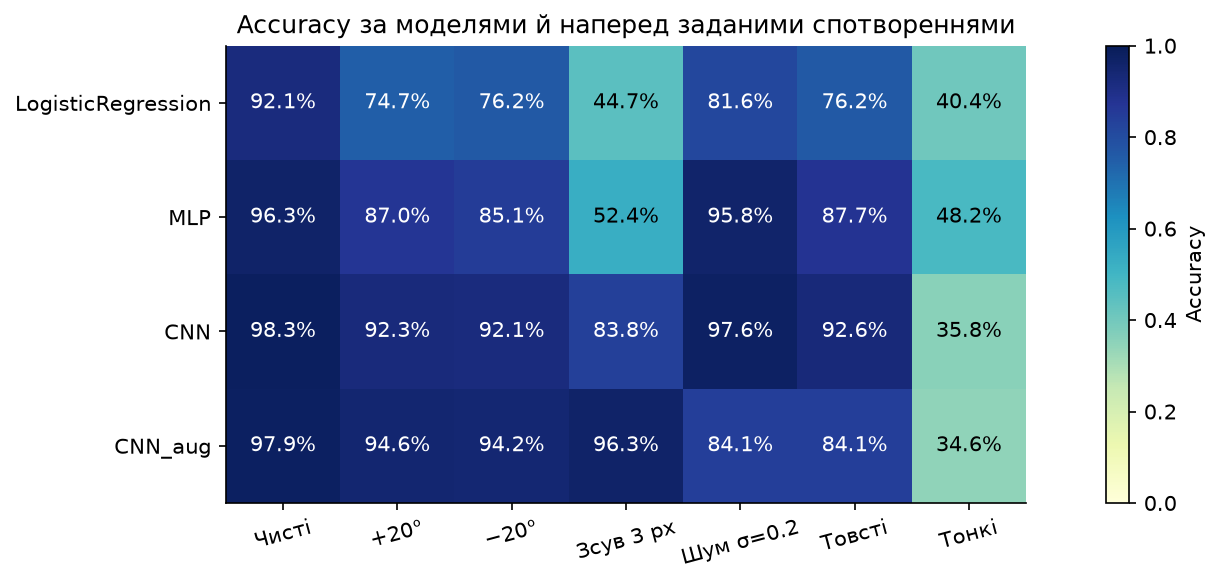

condition,clean,noise_020,rotate_minus20,rotate_plus20,shift_right3,thick,thin
name,,,,,,,
CNN,0.9829,0.9756,0.9212,0.9230,0.8378,0.9260,0.3580
CNN_aug,0.9790,0.8412,0.9421,0.9457,0.9627,0.8412,0.3461
LogisticRegression,0.9208,0.8159,0.7621,0.7471,0.4470,0.7624,0.4044
MLP,0.9626,0.9582,0.8513,0.8696,0.5242,0.8773,0.4822


In [10]:
display(Image(filename=str(OUT/'figures'/'corruption_examples.png')))
display(Image(filename=str(OUT/'figures'/'robustness.png')))
aggregate=pd.read_csv(OUT/'aggregated.csv')
display(aggregate.pivot(index='name',columns='condition',values='accuracy_mean').round(4))

## 9. Парні різниці та перевірка основної гіпотези
Спочатку обчислюємо CNN_aug − CNN для кожного seed, потім усереднюємо. Основний ефект — середнє трьох геометричних умов; чиста якість — окремий компроміс. Відсоткові пункти не слід плутати з відносними відсотками. Std між трьома seeds не є довірчим інтервалом.

,seed,condition,delta_accuracy,delta_macro_f1
0,17,clean,-0.0049,-0.00491
1,17,rotate_plus20,0.0147,0.01481
2,17,rotate_minus20,0.0190,0.01871
3,17,shift_right3,0.1171,0.11389
4,17,noise_020,-0.0911,-0.08455
5,17,thick,-0.0898,-0.07383
6,17,thin,-0.0659,-0.07325
7,42,clean,-0.0008,-0.00070
8,42,rotate_plus20,0.0228,0.02251
9,42,rotate_minus20,0.0270,0.02706


Геометрія: mean delta=+5.61 в.п.; std=1.33 в.п.
Чисті дані: mean delta=-0.39 в.п.


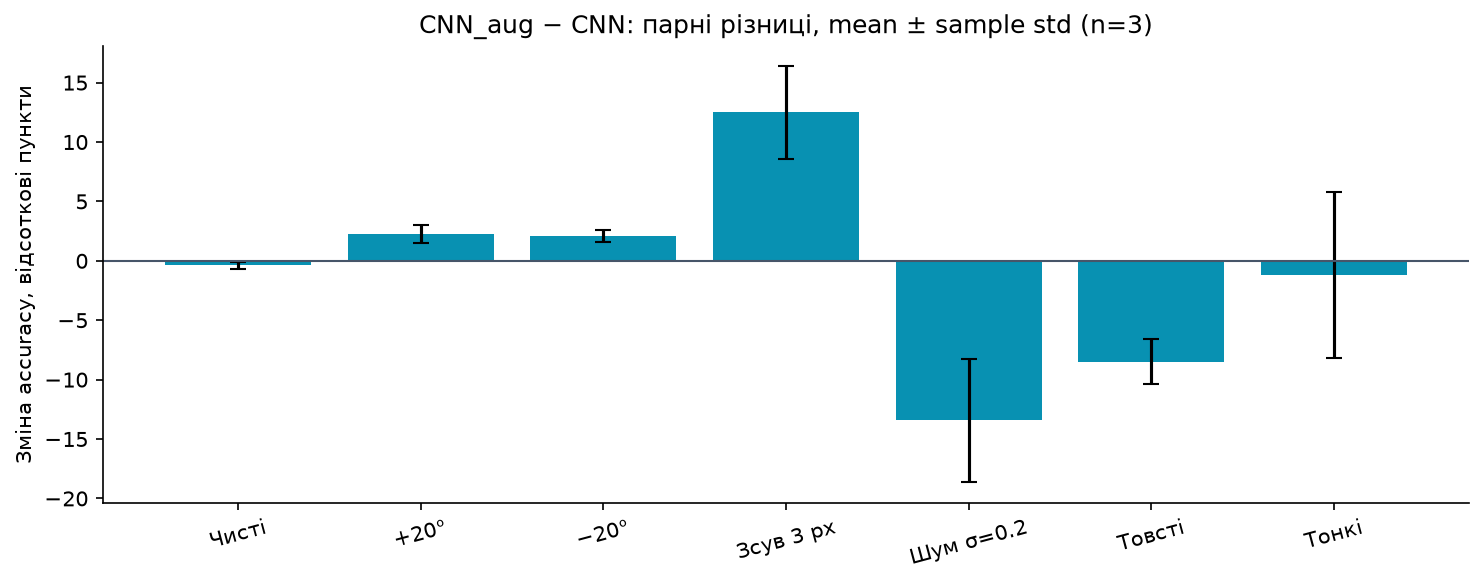

In [11]:
paired=pd.read_csv(OUT/'paired_deltas.csv')
display(paired.round(5))
primary=paired[paired.condition.isin(['rotate_plus20','rotate_minus20','shift_right3'])].groupby('seed').delta_accuracy.mean()
clean_effect=paired[paired.condition=='clean'].delta_accuracy
print(f'Геометрія: mean delta={primary.mean()*100:+.2f} в.п.; std={primary.std(ddof=1)*100:.2f} в.п.')
print(f'Чисті дані: mean delta={clean_effect.mean()*100:+.2f} в.п.')
display(Image(filename=str(OUT/'figures'/'augmentation_deltas.png')))

## 10. Аналіз помилок
Для кожного сімейства представник обирається за validation. Нижче — матриці помилок і перші неправильні прогнози моделі демонстрації в офіційному порядку test. У таблиці для обраного checkpoint наведено precision, recall і F1 кожної цифри.

{'name': 'CNN',
 'seed': 42,
 'validation_macro_f1': 0.981798220184244,
 'selected_epoch': 6,
 'training_seconds': 75.1644643000036,
 'parameters': 52138,
 'checkpoint': 'checkpoints/CNN_42.pt',
 'epochs_run': 6,
 'initial_weights_sha256': '5578779eddbaf5359e0eece1b4440334608d2db79fee33967389a1bcd32d2d49'}

,precision,recall,f1-score,support
0,0.9769,0.9918,0.9843,980.0000
1,0.9869,0.9982,0.9926,1135.0000
2,0.9761,0.9874,0.9817,1032.0000
3,0.9803,0.9871,0.9837,1010.0000
4,0.9839,0.9929,0.9883,982.0000
5,0.9842,0.9787,0.9815,892.0000
6,0.9968,0.9781,0.9874,958.0000
7,0.9739,0.9805,0.9772,1028.0000
8,0.9864,0.9682,0.9772,974.0000
9,0.9838,0.9623,0.9729,1009.0000


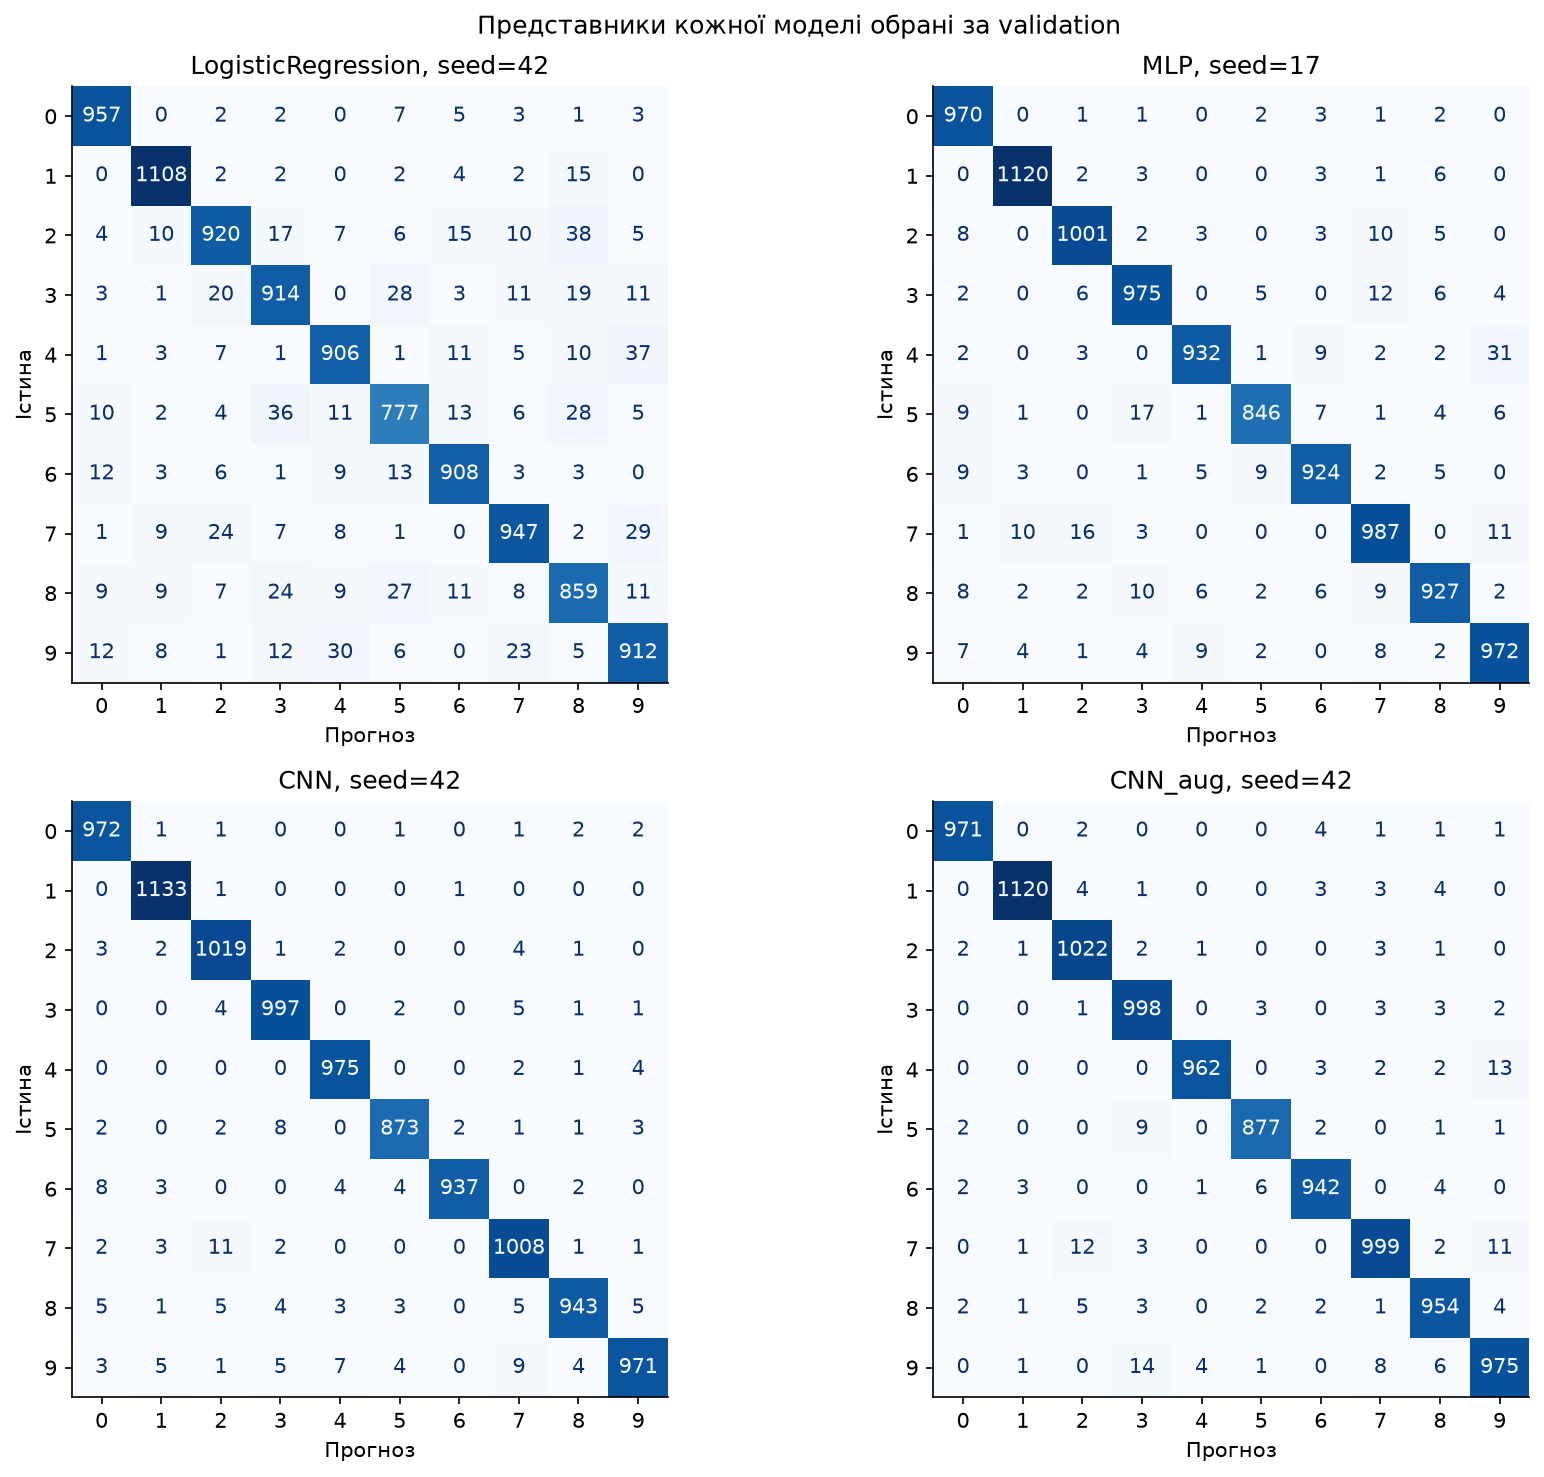

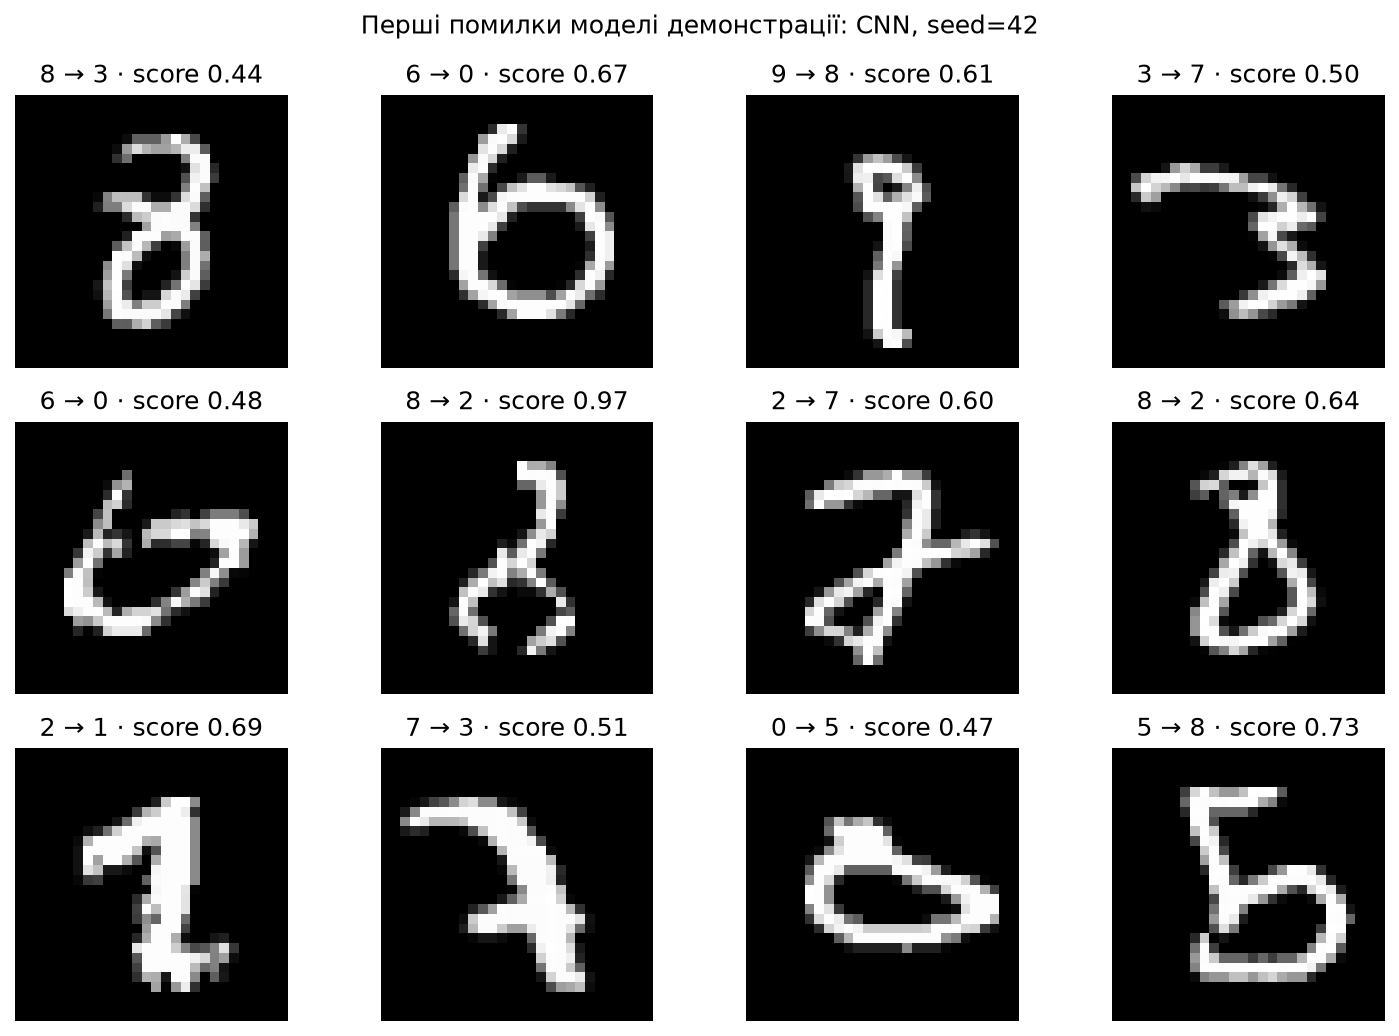

In [12]:
selected=json.loads((OUT/'demo_selection.json').read_text())
display(selected)
display(pd.read_csv(OUT/f"classes_{selected['name']}_{selected['seed']}.csv",index_col=0).round(4))
display(Image(filename=str(OUT/'figures'/'confusion_matrices.png')))
display(Image(filename=str(OUT/'figures'/'errors.png')))

## 11. Оцінки softmax і невизначеність
Softmax scores не є гарантованою впевненістю. Reliability diagram та 10-bin ECE — описова діагностика, без калібрування на test. Wilson-інтервал accuracy припускає незалежність test-прикладів і не враховує варіативність навчання чи зміну домену.

Accuracy 95% Wilson interval: [0.9800600917412722, 0.9851691194320026]


{'demo_errors': 172, 'demo_ece_10bins': 0.004018923535943017}

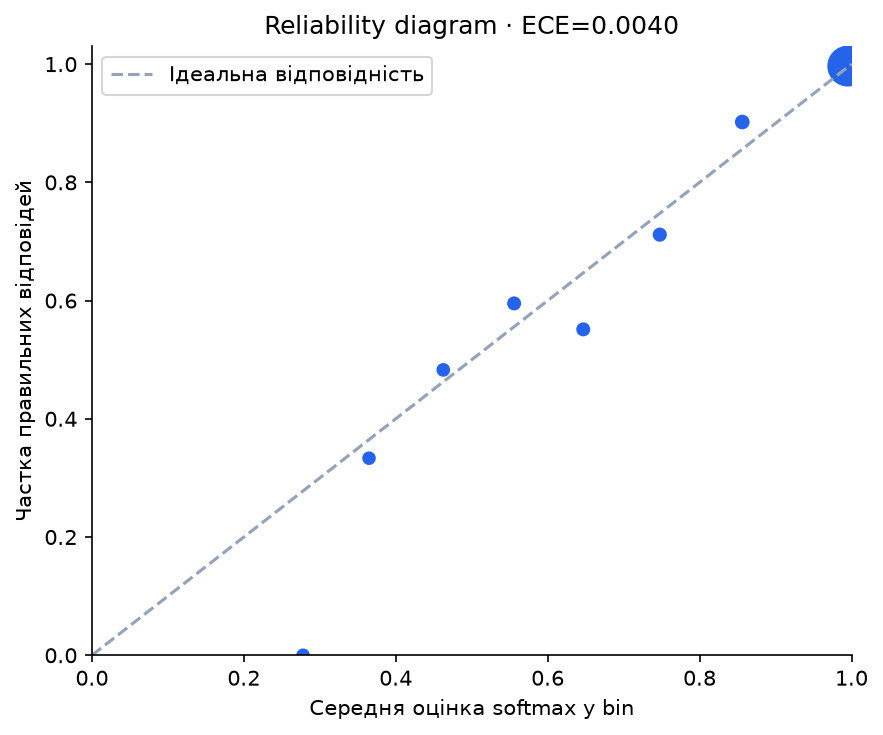

In [13]:
chosen=next(r for r in evaluation['runs'] if r['name']==selected['name'] and r['seed']==selected['seed'])
print('Accuracy 95% Wilson interval:',chosen['conditions']['clean']['accuracy_wilson_95'])
display(json.loads((OUT/'diagnostics.json').read_text()))
display(Image(filename=str(OUT/'figures'/'reliability.png')))

## 12. Демонстрація та висновки
Запуск у терміналі: `python app.py`, потім відкрити `http://127.0.0.1:8765`.
Полотно обрізається, вписується в 20×20, центрується в 28×28; користувач бачить вхід моделі й top-3. Порожнє полотно відхиляється. Це демонстрація, а не зовнішній розмічений тест.

Нижче завантажується повний звіт, автоматично сформований із фактичних результатів. Числа не підставлені вручну.

In [14]:
display(Markdown((ROOT/'REPORT.md').read_text(encoding='utf-8')))

# Розпізнавання рукописних цифр: порівняння моделей і дослідження аугментації

Автор: ____________________ · Група: ____________________

## Анотація

Досліджено багатокласову класифікацію зображень цифр на MNIST. Порівняно логістичну регресію, багатошаровий перцептрон (MLP), згорткову нейромережу (CNN) і ту саму CNN з геометричною аугментацією. Кожний нейронний варіант навчено з трьома seeds. Вибір checkpoint здійснено за validation macro-F1, а test використано для фінального оцінювання. Усі наведені числа отримано виконанням коду, а не задано вручну. CNN без аугментації отримала середню accuracy 98.29%, CNN з аугментацією — 97.90%. На трьох заздалегідь визначених геометричних спотвореннях середня парна зміна accuracy становила +5.61 відсоткового пункту. Це результат обмеженого обчислювального експерименту, а не гарантія якості на довільних рукописних зображеннях.

## 1. Постановка задачі та гіпотези

Вхід — одноканальне зображення 28×28; вихід — один із класів 0–9. Це supervised multiclass classification. Перша гіпотеза: локальна структура зображення, яку враховує CNN, дає кращу якість за лінійний класифікатор при нашому бюджеті навчання. Друга, основна гіпотеза: геометрична аугментація покращує стійкість CNN до поворотів і зсувів. Окремо вимірюється ціна такої стійкості на чистих даних. Основна узагальнювальна stress-метрика — рівнозважене середнє accuracy для +20°, −20° і зсуву праворуч 3 px; вона не є оцінкою частоти цих умов у реальному житті. Шум і товщина штриха — додаткові, а не навчальні перетворення.

## 2. Дані й запобігання витоку

Офіційна навчальна частина MNIST має 60000 прикладів. Стратифікованим поділом із seed=42 виділено 50000 train і 10000 validation. Офіційні 10000 test не включено ні в навчання, ні у вибір епохи. Усі моделі використовують однакові індекси. Пікселі переводяться з 0…255 у 0…1; для нейромереж додаткове фіксоване перетворення переводить їх у −1…1. Середні або дисперсії на validation/test не оцінюються. Аугментація застосовується виключно до навчальних mini-batches; validation лишається чистою. Індекси розбиття та SHA-256 завантажених архівів збережено. Відтворюваність випадкового поділу не означає незалежності авторів почерку.

![Дані](artifacts/figures/samples.png)

## 3. Моделі та навчання

Логістична регресія: C=1, L-BFGS, max_iter=300, tol=0.001, 784 вхідні ознаки. Це сильніший орієнтир, ніж випадковий прогноз; підбір параметрів цієї моделі не проводився. Модель sklearn отримує значення 0…1 без окремого StandardScaler.

MLP: Flatten → Linear(784,128) → ReLU → Dropout(0.2) → Linear(128,64) → ReLU → Linear(64,10).

CNN: Conv(1,8,3×3,padding=1) → ReLU → MaxPool(2) → Conv(8,16,3×3,padding=1) → ReLU → MaxPool(2) → Flatten → Linear(784,64) → ReLU → Dropout(0.2) → Linear(64,10). CNN_aug має ідентичну архітектуру.

Для всіх нейромереж: Adam, learning rate 0.001, weight_decay 0.0001, batch=256, шість епох, seeds 17/42/73. Функція втрат — CrossEntropyLoss над logits; softmax перед нею не застосовується. Градієнти обчислює autograd; крок оптимізації виконує готовий Adam. Для кожного запуску збережено checkpoint епохи з найбільшим validation macro-F1 (при рівності — раніша). Навчання триває всі шість епох: це вибір checkpoint, а не early stopping.

Для пар CNN/CNN_aug із тим самим seed початкові ваги ідентичні; їхні hashes збережено. DataLoader має незалежний generator для однакового порядку прикладів. Аугментація використовує окремий generator і не змінює потік випадковості dropout. Результати можуть залежати від бібліотек і процесора, тому версії зафіксовано. Використано CPU і два потоки PyTorch; однакова кількість епох не означає однакову кількість операцій чи час.

![Втрати](artifacts/figures/loss_curves.png)

Train loss вимірюється під час оновлень ваг із активним dropout (і аугментацією для CNN_aug); validation loss — після епохи в eval-режимі на чистих зображеннях. Тому ці криві не є ідентичними умовами вимірювання, і їхній розрив не слід автоматично називати перенавчанням.

## 4. Аугментація та контрольовані спотворення

Під час навчання CNN_aug кожне зображення незалежно отримує випадковий поворот у ±15° та масштаб 0.9…1.1. Параметр зсуву оберненої нормалізованої сітки змінюється в ±0.2: без поєднання з масштабом і поворотом це відповідає приблизно ±10% ширини. За спільної афінної трансформації фактичний прямий зсув може бути більшим, тому test-зсув 3 px не оголошуємо поза навчальним діапазоном. Перетворення виконується бібліотечними affine_grid/grid_sample з bilinear interpolation і чорним фоном. Test-повороти ±20° виходять за навчальні ±15°. Це перевірка обмеженого перенесення стійкості, а не повторення тих самих навчальних картинок.

Додаткові умови: адитивний Gaussian noise σ=0.2 у шкалі 0…1 з обрізанням до [0,1]; dilation та erosion квадратним ядром 3×3. Такі морфологічні перетворення можуть бути сильними й змінювати читабельність, тому їхній результат не слід трактувати як стійкість до будь-якого природного почерку. Всі моделі отримують однакові спотворені зображення. Кожна умова є окремою і не накладається поверх попередньої. Моделі після test не переналаштовувалися.

![Спотворення](artifacts/figures/corruption_examples.png)

## 5. Метрики та чистий test

Accuracy — частка правильних відповідей. Precision і recall обчислюються для кожної цифри; F1 — їх гармонічне середнє. Macro-F1 надає класам однакову вагу. Таблиця містить mean і sample std по трьох нейронних seeds; для єдиного запуску регресії std не визначено. Std між seeds описує варіативність навчання на фіксованому поділі, а не довірчий інтервал якості на всіх можливих даних.

| name | n | accuracy_mean | accuracy_std | macro_f1_mean | macro_f1_std |
| --- | --- | --- | --- | --- | --- |
| LogisticRegression | 1 | 0.9208 | — | 0.9197 | — |
| MLP | 3 | 0.9626 | 0.0025 | 0.9622 | 0.0025 |
| CNN | 3 | 0.9829 | 0.0014 | 0.9828 | 0.0014 |
| CNN_aug | 3 | 0.9790 | 0.0032 | 0.9790 | 0.0032 |

![Чистий test](artifacts/figures/clean_comparison.png)

Середня різниця CNN − LogisticRegression на чистому test: +6.21 відсоткового пункту. Це порівняння конкретних архітектур і фіксованих налаштувань, а не доказ загальної переваги всіх нейронних мереж над усіма класичними алгоритмами. Повні per-class precision/recall/F1 збережені у CSV для кожного запуску.

## 6. Основний експеримент: ефект аугментації

| condition | delta_accuracy_mean | delta_accuracy_std |
| --- | --- | --- |
| clean | -0.0039 | 0.0027 |
| rotate_plus20 | 0.0226 | 0.0079 |
| rotate_minus20 | 0.0209 | 0.0054 |
| shift_right3 | 0.1249 | 0.0387 |
| noise_020 | -0.1344 | 0.0520 |
| thick | -0.0848 | 0.0188 |
| thin | -0.0119 | 0.0698 |

У таблиці різниці в частках (0.01 = один відсотковий пункт). Парні різниці рахуються спочатку всередині seed, потім усереднюються. За основною геометричною stress-метрикою аугментація **покращила** accuracy: mean Δ=+5.61 в.п., sample std=1.33 в.п. На чистому test mean Δ=-0.39 в.п. Три seeds не дають підстав стверджувати статистичну значущість або гарантувати знак ефекту на іншому поділі.

![Ефект аугментації](artifacts/figures/augmentation_deltas.png)

![Стійкість](artifacts/figures/robustness.png)

## 7. Аналіз помилок та оцінок softmax

Представника кожного сімейства для матриць помилок обрано за validation, без пошуку найкращого test seed. Для демонстрації за тим самим правилом обрано CNN, seed=42, епоха=6. На чистому test він має 172 помилок. Для його accuracy Wilson 95% interval: [98.01%; 98.52%] за припущення незалежних прикладів; цей інтервал не враховує навчальну випадковість або зміну домену.

![Матриці](artifacts/figures/confusion_matrices.png)

![Помилки](artifacts/figures/errors.png)

Показано перші помилки в офіційному порядку test, а не підібрані вручну «гарні» приклади. Візуальна неоднозначність є можливою інтерпретацією, але не встановленою причиною. Діаграма надійності зі сталими десятьма bins дала ECE=0.0040; це лише описова, залежна від bins діагностика обраної моделі. Жодне калібрування на test не проводилося. Навіть високий softmax score не гарантує правильності для малюнка з іншого джерела.

![Reliability](artifacts/figures/reliability.png)

## 8. Практична демонстрація

Локальний застосунок app.py приймає малюнок із canvas, обрізає порожній фон, вписує штрих у поле 20×20, доповнює до 28×28 і центрує за центром мас. Після тієї самої фіксованої нормалізації модель повертає top-3 softmax scores і зображення, яке вона отримала. Порожні та некоректні входи відхиляються. Модель завантажується зі збереженого checkpoint, сервер слухає лише 127.0.0.1. Малюнки не зберігаються. Власний UI — демонстрація, а не розмічений зовнішній benchmark; точність на намальованих користувачем цифрах тут не оцінювалася.

## 9. Обмеження та подальша робота

1. Шість епох — фіксований CPU-бюджет, а не доведена збіжність кожної моделі. CNN_aug може потребувати довшого навчання; висновки обмежені цим бюджетом.
2. Один train/validation split і три seeds оцінюють лише частину невизначеності. Повторні розбиття та незалежні автори почерку підсилили б висновки.
3. MNIST містить підготовлені зображення; фотографії мають інший фон, світло, перспективу. Для них потрібні дані й окреме оцінювання.
4. Геометрична аугментація не навчає модель автоматично стійкості до шуму чи морфології. Результати для цих умов потрібно читати окремо.
5. Логістична регресія не мала пошуку гіперпараметрів, а нейромережі мають одну архітектуру й оптимізатор. Порівняння не вичерпує класів моделей.
6. ECE залежить від розбиття на bins; Wilson interval припускає незалежність test-прикладів; жодна метрика не заміняє перевірки нового домену.

Подальші експерименти: більший наперед визначений бюджет, кілька незалежних split, контроль кожного типу аугментації окремо, оцінювання на розміченому наборі малюнків нових авторів. Вони не видаються за виконані результати цієї роботи.

## 10. Висновки

Реалізовано повний цикл: отримання даних, контрольований поділ, навчання бібліотечних моделей, вибір checkpoint за validation, незалежне test-оцінювання, парне дослідження аугментації, аналіз помилок і інтерактивне застосування. Основний результат — не лише accuracy, а виміряний компроміс чистої якості та стійкості: геометричний ефект +5.61 в.п. при зміні чистої accuracy на -0.39 в.п. Всі цифри можна перевірити за збереженими прогнозами, історіями та вагами.

## 11. Розширення: цілі числа від 1 до 1000

### Постановка та реалізація

Модель цифр повторно використано для розпізнавання послідовностей довжиною від однієї до чотирьох цифр. 1000 окремих класів не навчалися. Пайплайн: широке полотно → очищення фону → поділ за вертикальною проєкцією → впорядкування зліва направо → передобробка кожної цифри → CNN → об'єднання top-1 прогнозів → перевірка діапазону.

Полотно UI має 840×240 пікселів. Поріг foreground — 40 у шкалі 0…255; видаляються 8-зв'язні компоненти площею меншою за max(6,0.002×кількість foreground-пікселів). Сусідні зайняті вертикальні ділянки об'єднуються, якщо порожній проміжок не перевищує max(4 px, round(0.035×висота foreground)). Це допомагає зберігати розірвані штрихи однієї цифри, але може помилково об'єднати надто близькі цифри. Повертаються рамки [x,y,width,height], входи моделі й top-3 кожної цифри. Геометрична сегментація є передобробкою; алгоритми класифікації та градієнти з нуля не реалізуються.

Нуль, провідні нулі та значення понад 1000 відхиляються. Наприклад, прогноз 1001 показується як 1001 із поясненням недопустимого діапазону, а не замінюється на «найближче дозволене» число. Більше чотирьох виділених ділянок викликає повідомлення про помилку. Підтримувана умова — одне число в один рядок із проміжками; перекриття, дотик і багаторядковий ввід надійно не підтримуються.

### Протокол синтетичної перевірки

Для кожного цілого числа 1…1000 створено рівно одну композицію з випадково обраних цифр **офіційного test MNIST**, seed=829. Ті самі вибрані glyphs використано у двох умовах: проміжок 18 px і нульовий проміжок між bounding rectangles. Висота glyph — 72 px, полотно — 500×120. Параметри сегментації за результатами перевірки не підбиралися; ваги CNN не змінювалися. Використано checkpoint, раніше обраний лише за validation.

Нульовий проміжок означає сусідство рамок, але не гарантує фізичний контакт штрихів: крайні пікселі можуть бути на різних рядках. Умова є контрольним складним прикладом для методу, що спирається на порожні стовпці.

Основна метрика — **exact-number accuracy**: відповідь правильна, тільки якщо вся послідовність точно відповідає істині та проходить перевірку діапазону. Додатково вимірюються правильна кількість цифр і збіг усіх впорядкованих рамок із відомими межами (IoU≥0.8). Контроль oracle-crop отримує правильні рамки, але використовує **те саме очищене зображення й ту саму передобробку/CNN**; це дозволяє дослідити внесок автоматичного визначення меж. Відмінність двох accuracy не є математично точним розкладом усіх помилок: іноді неправильна межа може випадково дати правильний прогноз.

| Метрика | Проміжок 18 px | Нульовий проміжок |
|---|---:|---:|
| Кількість чисел | 1000 | 1000 |
| Повністю правильні числа | 906 | 9 |
| Exact-number accuracy | 90.60% | 0.90% |
| Правильна кількість цифр | 98.30% | 0.90% |
| Усі рамки мають IoU≥0.8 | 97.80% | 0.90% |
| Exact-number accuracy з відомими межами | 92.30% | 92.30% |
| Accuracy цифр з відомими межами | 97.30% | 97.30% |
| Відхилення за діапазоном | 24 | 20 |

![Синтетичні числа та виділені рамки](artifacts/numbers/examples.png)

### Інтерпретація й обмеження

Навіть при хорошому розпізнаванні окремих цифр помилка одного символу робить усе число неправильним. Результати з проміжками показують сумарну якість сегментації й CNN за цим синтетичним протоколом. Результат із нульовим проміжком демонструє очікувану слабкість вертикальної проєкції; його не приховано й не використано для післятестового налаштування.

Це **не benchmark справжнього написання багатозначних чисел**: glyphs написані окремо, масштаб і розміщення стандартизовані, природні лігатури не представлені. Source-цифри повторно використовуються між числами, тому приклади залежні; їх також раніше застосовано в основному test-експерименті. Штучні композиції не є новим незалежним джерелом даних. Інтервали, що трактують усі 1000 чисел як незалежні, не наводяться. Для реальної оцінки потрібні розмічені цілі числа від нових авторів із зафіксованими умовами збору.

Наступний крок — окремо зібрати та оцінити такий набір; для цифр, що зливаються, розглянути learned segmentation або sequence recognition. Ці можливості не видаються за вже реалізовані. Навчання базових моделей і їхні test-результати залишаються такими, як у головному експерименті.


## Джерела та відтворення

- [Torchvision MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).
- [PyTorch: навчання моделей](https://docs.pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html).
- [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).
- [Grid sample](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.grid_sample.html).
- [scikit-learn: оцінювання](https://scikit-learn.org/stable/modules/model_evaluation.html).

Середовище фактичного запуску: {'python': '3.12.14', 'torch': '2.15.0+cpu', 'sklearn': '1.9.1', 'numpy': '2.5.4', 'pandas': '3.1.1', 'device': 'cpu', 'threads': 2}. Команди відтворення наведені в README. Артефакти містять конфігурацію, SHA-256 даних і checkpoint, індекси, історії, всі test-прогнози, таблиці та рисунки.


## 13. Розпізнавання чисел 1–1000
Для одного числа в рядок із проміжками повторно використовуємо digit CNN. Виділяємо цифри за вертикальною проєкцією, об'єднуємо дрібні внутрішні розриви, упорядковуємо зліва направо й перевіряємо ціле число. Неприпустимий прогноз не підміняється дозволеним. Порожній ввід і понад чотири сегменти відхиляються.

На головній сторінці застосунку тепер широке полотно; попередній режим однієї цифри доступний за `/digit`.

In [15]:
from inference import segment_number, predict_number, validate_number
display(Code(inspect.getsource(segment_number),language='python'))
display(Code(inspect.getsource(predict_number),language='python'))
for text in ['407','1000','1001','01','0']:
    print(text,'→',validate_number(text))

def segment_number(pixels):
    """Segment a spaced row using blank columns, not digit classification.

    Tiny 8-connected components are removed. Internal gaps up to max(4px,3.5%
    of ink height) are joined. Touching/adjacent glyphs cannot be reliably split.
    Boxes use [x,y,width,height].
    """
    clean,mask=number_foreground(pixels)
    ys=np.flatnonzero(mask.any(axis=1))
    merge_gap=max(4,round((ys[-1]-ys[0]+1)*.035))
    occupied=np.flatnonzero(mask.any(axis=0))
    groups=np.split(occupied,np.flatnonzero(np.diff(occupied)>merge_gap+1)+1)
    if len(groups)>4:
        raise ValueError('Знайдено більше чотирьох цифр. Напишіть одне число 1–1000.')
    parts=[]
    for columns in groups:
        x0,x1=int(columns[0]),int(columns[-1])+1
        rows=np.flatnonzero(mask[:,x0:x1].any(axis=1))
        y0,y1=int(rows[0]),int(rows[-1])+1
        crop=clean[y0:y1,x0:x1]
        # The existing preparation accepts arrays >=28 px on each axis.
        crop=np.pad(crop,((0,max(0,28-crop.shape[0])),(0,max(0,28-crop.shape[1]))))
        parts.append({'bbox':[x0,y0,x1-x0,y1-y0],'crop':crop})
    return parts

def predict_number(model,pixels):
    parts=segment_number(pixels)
    images=torch.cat([prepare_canvas(p['crop']) for p in parts])
    with torch.inference_mode():
        probabilities=model(normalize(images)).softmax(1)
    digits=[]
    for part,image,probability in zip(parts,images,probabilities):
        top=torch.topk(probability,3)
        digits.append({'bbox':part['bbox'],
                       'top3':[{'digit':int(i),'score':float(p)} for p,i in zip(top.values,top.indices)],
                       'preview':(image[0].numpy()*255).astype(int).tolist()})
    text=''.join(str(d['top3'][0]['digit']) for d in digits)
    number,error=validate_number(text)
    return {'text':text,'number':number,'valid':error is None,'message':error,
            'segmentation_count':len(digits),'digits':digits}

407 → (407, None)
1000 → (1000, None)
1001 → (None, 'Розпізнане число поза діапазоном 1–1000.')
01 → (None, 'Провідні нулі не підтримуються. Напишіть число без них.')
0 → (None, 'Розпізнане число поза діапазоном 1–1000.')


## 14. Синтетичний benchmark цілих чисел
Для всіх 1…1000 складено test-glyphs MNIST у двох фіксованих умовах: 18 px між рамками та нульовий проміжок. Контроль із відомими межами отримує те саме очищення та preprocessing. Це не справжні багатозначні рукописні зразки й не новий незалежний test: glyphs повторюються, джерело вже використане в основному експерименті.

,samples,numbers_min,numbers_max,exact_numbers,exact_number_accuracy,segmentation_accuracy_iou08,digit_count_accuracy,oracle_exact_number_accuracy,oracle_digits_correct,oracle_digits_total,oracle_digit_accuracy,range_rejections
spaced,1000.0,1.0,1000.0,906.0,0.906,0.978,0.983,0.923,2815.0,2893.0,0.973038,24.0
zero_gap,1000.0,1.0,1000.0,9.0,0.009,0.009,0.009,0.923,2815.0,2893.0,0.973038,20.0


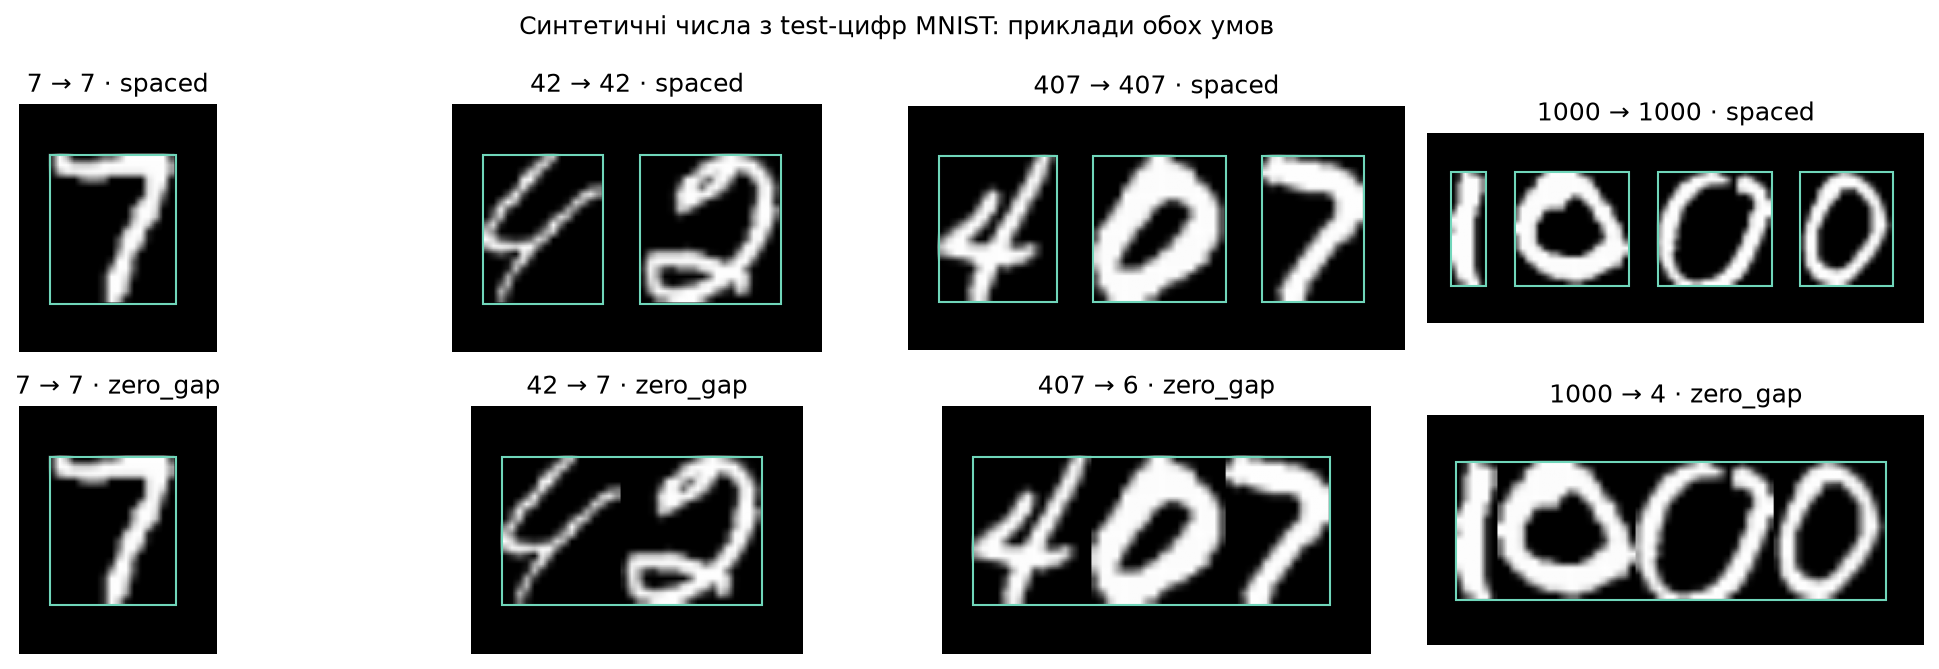

## 11. Розширення: цілі числа від 1 до 1000

### Постановка та реалізація

Модель цифр повторно використано для розпізнавання послідовностей довжиною від однієї до чотирьох цифр. 1000 окремих класів не навчалися. Пайплайн: широке полотно → очищення фону → поділ за вертикальною проєкцією → впорядкування зліва направо → передобробка кожної цифри → CNN → об'єднання top-1 прогнозів → перевірка діапазону.

Полотно UI має 840×240 пікселів. Поріг foreground — 40 у шкалі 0…255; видаляються 8-зв'язні компоненти площею меншою за max(6,0.002×кількість foreground-пікселів). Сусідні зайняті вертикальні ділянки об'єднуються, якщо порожній проміжок не перевищує max(4 px, round(0.035×висота foreground)). Це допомагає зберігати розірвані штрихи однієї цифри, але може помилково об'єднати надто близькі цифри. Повертаються рамки [x,y,width,height], входи моделі й top-3 кожної цифри. Геометрична сегментація є передобробкою; алгоритми класифікації та градієнти з нуля не реалізуються.

Нуль, провідні нулі та значення понад 1000 відхиляються. Наприклад, прогноз 1001 показується як 1001 із поясненням недопустимого діапазону, а не замінюється на «найближче дозволене» число. Більше чотирьох виділених ділянок викликає повідомлення про помилку. Підтримувана умова — одне число в один рядок із проміжками; перекриття, дотик і багаторядковий ввід надійно не підтримуються.

### Протокол синтетичної перевірки

Для кожного цілого числа 1…1000 створено рівно одну композицію з випадково обраних цифр **офіційного test MNIST**, seed=829. Ті самі вибрані glyphs використано у двох умовах: проміжок 18 px і нульовий проміжок між bounding rectangles. Висота glyph — 72 px, полотно — 500×120. Параметри сегментації за результатами перевірки не підбиралися; ваги CNN не змінювалися. Використано checkpoint, раніше обраний лише за validation.

Нульовий проміжок означає сусідство рамок, але не гарантує фізичний контакт штрихів: крайні пікселі можуть бути на різних рядках. Умова є контрольним складним прикладом для методу, що спирається на порожні стовпці.

Основна метрика — **exact-number accuracy**: відповідь правильна, тільки якщо вся послідовність точно відповідає істині та проходить перевірку діапазону. Додатково вимірюються правильна кількість цифр і збіг усіх впорядкованих рамок із відомими межами (IoU≥0.8). Контроль oracle-crop отримує правильні рамки, але використовує **те саме очищене зображення й ту саму передобробку/CNN**; це дозволяє дослідити внесок автоматичного визначення меж. Відмінність двох accuracy не є математично точним розкладом усіх помилок: іноді неправильна межа може випадково дати правильний прогноз.

| Метрика | Проміжок 18 px | Нульовий проміжок |
|---|---:|---:|
| Кількість чисел | 1000 | 1000 |
| Повністю правильні числа | 906 | 9 |
| Exact-number accuracy | 90.60% | 0.90% |
| Правильна кількість цифр | 98.30% | 0.90% |
| Усі рамки мають IoU≥0.8 | 97.80% | 0.90% |
| Exact-number accuracy з відомими межами | 92.30% | 92.30% |
| Accuracy цифр з відомими межами | 97.30% | 97.30% |
| Відхилення за діапазоном | 24 | 20 |

![Синтетичні числа та виділені рамки](artifacts/numbers/examples.png)

### Інтерпретація й обмеження

Навіть при хорошому розпізнаванні окремих цифр помилка одного символу робить усе число неправильним. Результати з проміжками показують сумарну якість сегментації й CNN за цим синтетичним протоколом. Результат із нульовим проміжком демонструє очікувану слабкість вертикальної проєкції; його не приховано й не використано для післятестового налаштування.

Це **не benchmark справжнього написання багатозначних чисел**: glyphs написані окремо, масштаб і розміщення стандартизовані, природні лігатури не представлені. Source-цифри повторно використовуються між числами, тому приклади залежні; їх також раніше застосовано в основному test-експерименті. Штучні композиції не є новим незалежним джерелом даних. Інтервали, що трактують усі 1000 чисел як незалежні, не наводяться. Для реальної оцінки потрібні розмічені цілі числа від нових авторів із зафіксованими умовами збору.

Наступний крок — окремо зібрати та оцінити такий набір; для цифр, що зливаються, розглянути learned segmentation або sequence recognition. Ці можливості не видаються за вже реалізовані. Навчання базових моделей і їхні test-результати залишаються такими, як у головному експерименті.


In [16]:
if not (OUT/'numbers'/'summary.json').exists():
    subprocess.run([sys.executable,str(ROOT/'evaluate_numbers.py')],check=True,cwd=ROOT)
number_summary=json.loads((OUT/'numbers'/'summary.json').read_text())
display(pd.DataFrame(number_summary['layouts']).T)
display(Image(filename=str(OUT/'numbers'/'examples.png')))
from number_report import build_section
display(Markdown(build_section()))

## Відповідність завданню
Обрана задача — класифікація; дані — MNIST; навчання — sklearn і PyTorch; оцінювання — validation/test, accuracy, macro-F1, per-class report, матриці, повторні запуски й stress tests. Немає реалізації ML-алгоритмів або градієнтів з нуля. Додатково надані модулі, ваги, протокол, графіки, звіт і локальний застосунок.

Джерела: [MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html), [PyTorch training](https://docs.pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html), [scikit-learn metrics](https://scikit-learn.org/stable/modules/model_evaluation.html).